# **Project Goals**

This is the project of solely myself: Barek Webb. I will be examining data sets relating to state public finances with a focus on Louisiana. I will be using one data set as of this moment, the annual survey of state government finances, or asfin for short. I hope to better understand the fiscal health of Louisiana, and compare it to other states. Eventually I will most likely use FRED to import other data sets to compare Louisiana to national averages. I hypothesize that the state of Louisiana has likely not improved it's financial health from 2012 to 2024. When conducting my exploratory data analysis, and further investigation I will bring forward definitions of what good financial health of a state means, as this can vary. The website is linked here...

In [12]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# importing the first data set from asfin
LA_df = pd.read_csv('LATimeSeries.csv')



# **ASFIN Data**

The ASFIN data, or the annual survey of state government finances is the first data set that I will use. I have downloaded this data from the United States Census Bureau. The ASFIN data I have downloaded is filtered. I selected the years from 2012 to 2024 only for the state of Louisiana. After that filter, I then decided to focus on four areas, Debt, Interest, Revenue, and Expenditure. This data set contains over 200 data points measuring various financial indicators for Lousiana. This data set was chosen and filtered to focus explicity on the state of Louisiana. For now, I want to ask questions relating to trends on debt, the burden of debt, and the stability of the deficit, or surplus, if that is what we find. Further questions for the project will have a larger scope, comparing Louisiana to other states and the nation at large. Further data might be required, depending on how this data approaches my initial questions about Louisiana. Below is the link that will take you to all of these filters.

https://data.census.gov/table/GOVSSTATEFINTIMESERIES.GS00STATEFIN01?q=GS00STATEFIN&g=040XX00US22&nkd=AGG_DESC~SF0001:SF0002:SF0036:SF0091:SF0094:SF0132:SF0401:SF0455:SF0456:SF0457:SF0458:SF0459:SF0460:SF0461:SF0462:SF0463:SF0464:SF0465:SF0466:SF0467:SF0471,time~2012:2013:2014:2015:2016:2017:2018:2019:2020:2021:2022:2023:2024&tableFilters=AMOUNT~AND(0g:0g)&cols=time:NAME:AGG_DESC:ITEM_CODE:AGG_DESC_LABEL:ITEM_CODE_LABEL:GOVTYPE_LABEL:CATEGORY_LABEL:AMOUNT:AMOUNT_CV



In [2]:
LA_df.head()

,Year (time),Geographic Area Name (NAME),Aggregate Description (AGG_DESC),Item Code (ITEM_CODE),Meaning of Aggregate Description (AGG_DESC_LABEL),Meaning of Item Code (ITEM_CODE_LABEL),Meaning of Type of Government (GOVTYPE_LABEL),Meaning of Category (CATEGORY_LABEL),"Amount ($1,000) (AMOUNT)",Coefficient of Variation for Amount (percent) (AMOUNT_CV)
0,2012,Louisiana,SF0001,AGG,Revenue - Total Revenue,Aggregate,State,Revenue,"26,938,141",0
1,2013,Louisiana,SF0001,AGG,Revenue - Total Revenue,Aggregate,State,Revenue,"33,250,908",0
2,2014,Louisiana,SF0001,AGG,Revenue - Total Revenue,Aggregate,State,Revenue,"34,529,120",0
3,2015,Louisiana,SF0001,AGG,Revenue - Total Revenue,Aggregate,State,Revenue,"28,134,018",0
4,2016,Louisiana,SF0001,AGG,Revenue - Total Revenue,Aggregate,State,Revenue,"26,728,156",0


The data comes out rather nice and is easy to follow as a whole. There are three things that I want to do immediately, though. We have three columns that are redundant. Column 'Meaning of Item Code' and column 'Coefficient..' as well as column 'Geographic Area Name' are basically useless so lets get rid of them. We already know this is state data for Louisiana, and the coefficient column only has 0s.

In [3]:
# .drop columns
LA_df = LA_df.drop(columns = ['Meaning of Type of Government (GOVTYPE_LABEL)', 'Coefficient of Variation for Amount (percent) (AMOUNT_CV)', 'Geographic Area Name (NAME)'])

The ASFIN data is great, but it does violate a tidy data principle. The table LA_df has many types of observational units. We should create a new DF for each type of 'Meaning of Category' we will put the category 'Cash and Securities' with the category 'Debt' because the 'Cash and Security Holdings' offset the debt. Let's create three new dataframes.


In [4]:
# we cannot astype 'Amount ($1,000) (AMOUNT)' to float until we deal with the commas which float cannot work with to convert
# we should start now to get rid of the commas before we create the new dfs


# lets change the entire column of 'Amount ($1,000) (AMOUNT)'
LA_df['Amount ($1,000) (AMOUNT)'] = [
    float(str(i).replace(',', ''))
    for i in LA_df['Amount ($1,000) (AMOUNT)']
]

# new dfs
# df for revenue using a boolean mask
Revenue_df = LA_df[LA_df['Meaning of Category (CATEGORY_LABEL)']=='Revenue']

# df for expenses
Expenditure_df = LA_df[LA_df['Meaning of Category (CATEGORY_LABEL)']== 'Expenditure']

# df for debt
Debt_df = LA_df[
    (LA_df['Meaning of Category (CATEGORY_LABEL)']== 'Debt') |
    ( LA_df['Meaning of Category (CATEGORY_LABEL)']== 'Cash and Securities')
]

In [5]:
# lets take a look at the df to check them out
# lets start with Revenue
# lets check the data types
Revenue_df.dtypes

,0
Year (time),int64
Aggregate Description (AGG_DESC),object
Item Code (ITEM_CODE),object
Meaning of Aggregate Description (AGG_DESC_LABEL),object
Meaning of Item Code (ITEM_CODE_LABEL),object
Meaning of Category (CATEGORY_LABEL),object
"Amount ($1,000) (AMOUNT)",float64


In [7]:
# lets check debt
Debt_df.dtypes

,0
Year (time),int64
Aggregate Description (AGG_DESC),object
Item Code (ITEM_CODE),object
Meaning of Aggregate Description (AGG_DESC_LABEL),object
Meaning of Item Code (ITEM_CODE_LABEL),object
Meaning of Category (CATEGORY_LABEL),object
"Amount ($1,000) (AMOUNT)",float64


In [8]:
# lets check expenses
Expenditure_df.dtypes

,0
Year (time),int64
Aggregate Description (AGG_DESC),object
Item Code (ITEM_CODE),object
Meaning of Aggregate Description (AGG_DESC_LABEL),object
Meaning of Item Code (ITEM_CODE_LABEL),object
Meaning of Category (CATEGORY_LABEL),object
"Amount ($1,000) (AMOUNT)",float64


# ** Exploratory Data Analysis**

Unlike our Federal government, most US states face restrictions with their budgets. Louisiana, does require a balanced budget, or, spending that is not allowed to surpass revenue forecasts created by the state of Louisiana's revenue estimating conference (https://investlouisiana.org/the-budget-actors/). Further restrictions on spending arise because a large portion of the budget comes from the Federal government (https://investlouisiana.org/budget-basics/).

So, we're likely not going to see any large deficits within the data, but the state of Louisiana, like any other state, needs to take on debt for various projects. Is there a general trend in the total debt outstanding from 2012 to 2024?




In [11]:
# lets create a boolean mask to check the average 'Debt - Total Debt Outstanding'

avg_debtovt = Debt_df[Debt_df['Meaning of Aggregate Description (AGG_DESC_LABEL)'] == 'Debt - Total Debt Outstanding']['Amount ($1,000) (AMOUNT)'].mean()

# lets print it out
print(avg_debtovt)

17532968.307692308


The average total outstanding debt that the state of Louisiana carried for each year from 2012 to 2024 was 17,532,968.307692308 billion dollars. We must remember 'Amount ($1,000) (AMOUNT)' is in thousands. Without knowing anything else, this seems to be a reasonable figure. Let's look at how this number changed over our time period.

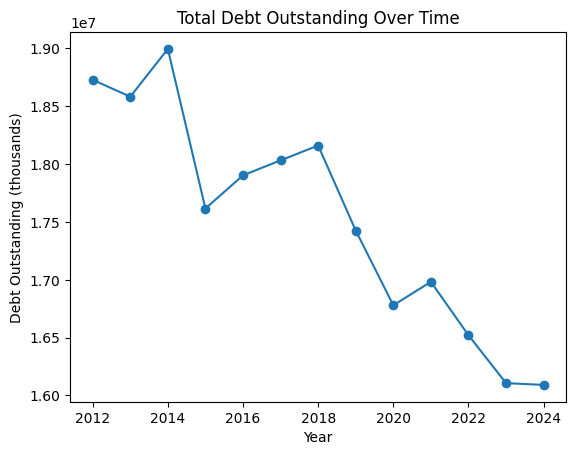

In [19]:
# plot the chart

# filter for 'Debt - Total Debt Outstanding'
debt_ovt_mask = Debt_df['Meaning of Aggregate Description (AGG_DESC_LABEL)'] == 'Debt - Total Debt Outstanding'

# plot the values over time
plt.plot(
    Debt_df.loc[debt_ovt_mask, 'Year (time)'],
    Debt_df.loc[debt_ovt_mask, 'Amount ($1,000) (AMOUNT)'],
    marker='o'
)

# fixing up the graph
plt.xlabel('Year')
plt.ylabel('Debt Outstanding (thousands)')
plt.title('Total Debt Outstanding Over Time')
plt.show()

This shows us a downward trend. Matplot defaulted the y axis to start at 1.6, which is 16 billion to the highest point of 1.9 which is 19 billion. Without knowing general trends accross other states and other states like Louisiana, this trend seems to begin our picture with a positive note. From 1.87 to 1.60 over our time frame. Now, a 2 billion decerase in total debt over twelve years is nothing substantially large, but it seems like a good indicator that Louisiana cares somewhat about her debt!

A good next step to better understand the debt, is what the actual burden of this debt starts to look like for the state. Generally speaking the cost of debt for a state in our nation should be much lower than the Federal level. Let's see what our data tells us about this.

In [31]:
# for interest on debt we care about 'Expenditure - Direct Expenditure - General Expenditure - Interest on General Debt'
# for total revenue we care about 'Revenue - Total Revenue'

# interest as a share of revenue can tell us the ratio of a state government's income that is used to pay off debt

# well use boolean mask to get the amounts

# boolean mask for revenue and interest
interest_ovtmask = (
    Expenditure_df['Meaning of Aggregate Description (AGG_DESC_LABEL)']
    == 'Expenditure - Direct Expenditure - General Expenditure - Interest on General Debt'
)

# revenue
revenue_ovtmask = (
        Revenue_df['Meaning of Aggregate Description (AGG_DESC_LABEL)']
    == 'Revenue - Total Revenue'
)

#  getting the totals for each year

interest_LAovt = (
    Expenditure_df.loc[interest_ovtmask]
    .set_index('Year (time)')['Amount ($1,000) (AMOUNT)']
)

revenue_LAovt = (
    Revenue_df.loc[revenue_ovtmask]
    .set_index('Year (time)')['Amount ($1,000) (AMOUNT)']
)

# lets create interest_rev_la
interest_rev_la = (interest_LAovt / revenue_LAovt)

print(interest_rev_la)


Year (time)
2012    0.033337
2013    0.025535
2014    0.023196
2015    0.030372
2016    0.032873
2017    0.025471
2018    0.023783
2019    0.022455
2020    0.021834
2021    0.018619
2022    0.014885
2023    0.012832
2024    0.010344
Name: Amount ($1,000) (AMOUNT), dtype: float64


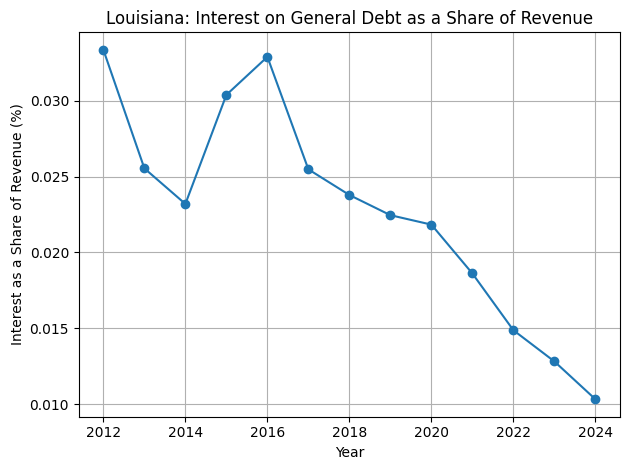

In [32]:
# lets plot it

# plot interest as a share of revenue over time
interest_rev_la.sort_index().plot(marker='o')

plt.xlabel('Year')
plt.ylabel('Interest as a Share of Revenue (%)')
plt.title('Louisiana: Interest on General Debt as a Share of Revenue')
plt.grid(True)
plt.tight_layout()
plt.show()

The general trend is again positive in the sense that Louisiana has a healthy ratio of interest as a share of revenue. We see a percentage of roughly over 3 percent in 2012 to the low end of 1 percent in 2024. It is likely highly correlated with the total amount of Debt - Total Debt Outstanding. We can continue to see the same volatility from 2012 to 2016, and the general decrease of the burden of debt. Louisiana, is likely owing less debt, and so we this general trend in the data.

How correlated are these two new data points we have?

In [43]:
# using correlation on interest_rev_la and debt_ovt_mask

# filter for 'Debt - Total Debt Outstanding'
debt_ovt_mask = (
    Debt_df['Meaning of Aggregate Description (AGG_DESC_LABEL)']
    == 'Debt - Total Debt Outstanding'
)

# filter for the amount of the 'Debt - Total Debt Outstanding'
debt_ovt = (
    Debt_df.loc[debt_ovt_mask]
    .set_index('Year (time)')['Amount ($1,000) (AMOUNT)']
)

# combining the two var into a new df
df_debt_corr = pd.concat([
    debt_ovt.rename('total_debt'),
    interest_rev_la.rename('interest_rev_la')
], axis=1).dropna()

# lets see what we get
matrix = df_debt_corr.corr()
print(matrix)


                 total_debt  interest_rev_la
total_debt         1.000000         0.776981
interest_rev_la    0.776981         1.000000


As we can see from the correltion table, it is rather high. We cannot assume causation! What we can tell is that generally years with higher total debt oustanding tend to coincide for years with higher costs for carrying that debt.

One last part of exploratory analysis we can do is look at the general pattern for revenue for the state of Louisiana.

In [45]:
# lets start by looking at the average revenue brought in from 2012 to 2024
avg_revovt = Revenue_df[Revenue_df['Meaning of Aggregate Description (AGG_DESC_LABEL)'] == 'Revenue - Total Revenue']['Amount ($1,000) (AMOUNT)'].mean()

# lets print it out
print(avg_revovt)



35583459.461538464


Over the time period of 2012 to 2024, Louisiana brought in on average 35,583,459.461538464 billion dollars per year. Let's see if there is a trend in this data.

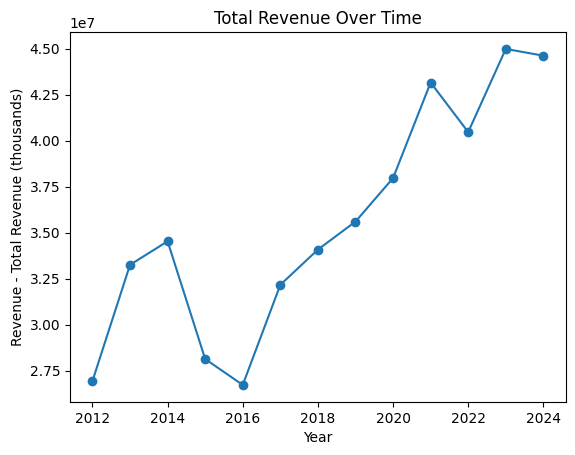

In [47]:
# plot the chart

# filter for 'Debt - Total Debt Outstanding'
rev_ovt_mask = Revenue_df['Meaning of Aggregate Description (AGG_DESC_LABEL)'] == 'Revenue - Total Revenue'

# plot the values over time
plt.plot(
    Revenue_df.loc[rev_ovt_mask, 'Year (time)'],
    Revenue_df.loc[rev_ovt_mask, 'Amount ($1,000) (AMOUNT)'],
    marker='o'
)

# fixing up the graph
plt.xlabel('Year')
plt.ylabel('Revenue - Total Revenue (thousands)')
plt.title('Total Revenue Over Time')
plt.show()

As we can tell from this trend, revenue is up from roughly 26 billion dollars in 2012 to roughly 45 billion dollars in 2024. This seems to be a healthy growth in revenue for Louisiana. We again see some volatility from 2012 to 2016. This could be examined further, in relation to the debt.

# EDA wrap up

So far we have analyzed some general debt trends as well as revenue for Louisiana. Both our debt and revenue trends appear at a surface to be positive for the state of Louisiana. This might seem to be a surprise, and it is, to a certain extent. However, without knowing about general trends for other states and national or regional averages, our current picture only shows us so much about what is going on.

We will have to dive much deeper into the fiscal health of Louisiana. I will have to bring in more data sets, probably from FRED. Something like revenue increasing may or may not correlate strongly with how households in Louisiana are faring financially. Also, our initial surprise might lead to be true, to a certain extent. Towards the end of this tutorial I will have laid out a stronger score card to determine if the state of Louisiana's finances are better in 2024 than they were in 2012. There is also something interesting that happened in 2012 to 2016, I will investigate this as well.

